### Bloco 1 · Abertura

# Qual a “melhor” combinação de pesos?

**Python Finance Lab · Aula 6 · Capítulo para estudo.**

Até aqui, a referência é uma carteira com 10% em cada uma das dez ações. A correlação e as covariâncias ajudam a entender por que mudar os pesos altera sua volatilidade. Agora a pergunta é: outra combinação parece melhor nas estimativas históricas? E o que acontece quando essa escolha é levada ao período seguinte?

Vamos sortear 20 mil carteiras, sem venda a descoberto, usando apenas os retornos do período de estimação. A nuvem risco × retorno aproxima a região de oportunidades, mas não calcula toda a fronteira eficiente nem prova que encontramos o ótimo global. Depois, vamos confrontar três escolhas com um período separado de teste. O NumPy entra para calcular milhares de combinações de uma vez.

Esta é a cópia de produção com a harmonização do Sharpe autorizada pelo usuário. Os arquivos recebidos foram preservados; a coleta foi substituída por leitura dos snapshots congelados fornecidos com a aula. Os resultados abaixo são específicos desses dados, não previsões. **Conteúdo educacional, sem recomendação de investimento.**

### Bloco 2 · O vocabulário da aula

**Retorno esperado** é uma estimativa, aqui a média amostral diária multiplicada por 252. Não é promessa e não é CAGR. A **matriz de covariância** contém variâncias na diagonal e covariâncias fora dela; ela descreve a volatilidade conjunta neste modelo, não todos os riscos de investir.

A **fronteira eficiente** é o conjunto de carteiras factíveis não dominadas: não há outra carteira factível com retorno esperado pelo menos tão alto e volatilidade no máximo igual, com melhora estrita em uma dessas dimensões. Sua parte eficiente acima da carteira de mínima variância seleciona a melhor troca entre retorno esperado e volatilidade para as restrições adotadas. Uma nuvem finita de sorteios não identifica esse conjunto contínuo.

A **carteira de mínima variância do modelo** minimiza a variância com pesos não negativos e soma igual a 1. Nesta aula, “Mínima variância (sorteio)” significa apenas a menor volatilidade **entre as 20 mil sorteadas**. O bloco 19 compara esse resultado com um mínimo numérico da biblioteca, sujeito às tolerâncias do solver.

O **Sharpe** usa os retornos em excesso ao CDI em cada intervalo: média desses excessos dividida por seu desvio padrão amostral, anualizada por raiz de 252. “Máximo Sharpe (sorteio)” é o maior valor **entre as sorteadas**, não uma afirmação sobre todas as carteiras possíveis. Como o CDI varia, o desvio dos excessos não é, em geral, idêntico ao desvio dos retornos da carteira.

**Sem venda a descoberto** significa pesos maiores ou iguais a zero e soma 1. A Dirichlet usada aqui produz pesos positivos; o conjunto permitido também inclui zeros. **Erro de estimação** é a distância entre um parâmetro estimado e o que se deseja conhecer. A escolha pode amplificar erros das médias e das covariâncias. **Dentro da amostra** é o período usado na escolha; **fora da amostra** é o período posterior reservado ao teste. Um teste não transforma estimativas em certezas.

### Bloco 3 · As contas da aula

Seja $R_{t,i}$ o retorno simples do ativo $i$ no intervalo $t$, e $r_{f,t}$ o retorno do CDI acumulado **no mesmo intervalo entre duas datas de preços**. Os pesos $w_i$ são os pesos-alvo restaurados diariamente, sem custos:

$$\sum_i w_i=1,\quad w_i\geq0,\qquad R_{p,t}=\sum_i w_iR_{t,i}.$$

Para o retorno esperado e a volatilidade dos ativos, usamos:

$$\mu=252\,\overline{R},\quad \Sigma=252\,\operatorname{Cov}_{ddof=1}(R),\qquad \mu_p=w^\top\mu,\quad \sigma_p=\sqrt{w^\top\Sigma w}.$$

Para o Sharpe, construímos $E_{t,i}=R_{t,i}-r_{f,t}$, $\mu_E=252\,\overline{E}$ e $\Sigma_E=252\,\operatorname{Cov}_{ddof=1}(E)$. Como os pesos somam 1, o excesso da carteira é $E_{p,t}=w^\top E_t$. Assim:

$$S_p=\sqrt{252}\frac{\overline{E_p}}{s(E_p)}=\frac{w^\top\mu_E}{\sqrt{w^\top\Sigma_Ew}}.$$

A taxa de referência descritiva é $252\,\overline{r_f}$, não o retorno composto anual do CDI. Mantemos a covariância de **retornos dos ativos** para a volatilidade exibida nos gráficos e para a mínima variância, e a covariância de **excessos** apenas no denominador do Sharpe. A regra de raiz de 252 é a convenção de anualização da aula; dependência temporal pode limitar essa interpretação.

No teste, a cota é $Q_t=\prod_{u\leq t}(1+R_{p,u})$, com ponto inicial igual a 1. O retorno composto anual realizado é $\operatorname{CAGR}=(Q_T/Q_0)^{1/a}-1$, em que $a$ é o número de dias corridos dividido por 365,25. Ele aparece somente na coluna de retorno realizado; **não entra no numerador do Sharpe**.

**Exemplo de diversificação.** Duas ações com médias anuais de 10% e 20%, volatilidades de 15% e 30% e correlação 0,2 têm covariância $0,2\times0,15\times0,30=0,009$. Com pesos de 50%, a média é 15%, a variância é $0,5^2\times0,0225+0,5^2\times0,09+2\times0,5\times0,5\times0,009=0,032625$ e a volatilidade é aproximadamente 18,06%. A volatilidade não é a média simples das volatilidades (22,5%). Variância tem unidade de retorno ao quadrado; volatilidade é apresentada em % e Sharpe é adimensional.

### Bloco 4 · Importar as bibliotecas

O NumPy (`np`) oferece arrays e operações numéricas vetorizadas; o pandas (`pd`) organiza séries e tabelas com datas e rótulos; o Matplotlib desenha os gráficos. `Path` e `json` fazem parte da biblioteca padrão e leem os arquivos locais. Como não haverá coleta nesta cópia, os imports de `yfinance` e `requests` deixam de ser necessários.

Execute as células de cima para baixo, no diretório que contém o notebook e a pasta `dados`. A célula apenas importa bibliotecas e normalmente não produz saída. As dependências e as instruções para reprodução estão em `ALTERACOES_AULA06.md`.

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

### Bloco 5 · As premissas

A janela de preços começa em 01/10/2021. A estimação vai até 30/09/2024 e o teste começa em 01/10/2024, terminando em 30/09/2026. O primeiro retorno exige dois preços: por isso o primeiro retorno de estimação é em 04/10/2021, não em 01/10/2021.

Mantemos as dez ações, 20 mil carteiras e semente 42. O sublinhado em `20_000` é apenas um separador visual. `ORDEM_ATIVOS` fixa explicitamente a ordem alfabética dos códigos sem `.SA`, preservando a ordem do snapshot e a associação original entre números sorteados e ativos. A lista `ACOES` identifica o universo; não basta ter os mesmos nomes se a ordem dos arrays mudar. Esta célula define valores e não imprime resultados.

In [2]:
ACOES = [
    "ITUB4.SA", "VALE3.SA", "PETR4.SA", "WEGE3.SA", "ABEV3.SA",
    "EGIE3.SA", "SUZB3.SA", "RADL3.SA", "VIVT3.SA", "TOTS3.SA",
]
DATA_INICIO = "2021-10-01"
FIM_ESTIMACAO = "2024-09-30"     # último dia usado para escolher os pesos
INICIO_TESTE = "2024-10-01"      # primeiro dia do teste
DATA_FIM = "2026-09-30"
N_CARTEIRAS = 20_000
SEMENTE = 42
# Uma ordem explícita para preços, médias, covariâncias e pesos.
ORDEM_ATIVOS = sorted(acao.removesuffix(".SA") for acao in ACOES)

### Bloco 6 · Os dados congelados

A execução lê `dados/precos_execucao.csv` e `dados/cdi_sgs12.json`, os snapshots já congelados para esta produção. Não há nova chamada ao Yahoo Finance ou ao Banco Central. Os preços vêm da execução identificada da coleta ajustada; reproduzir essa coleta em outra data pode gerar revisões históricas. Congelar o arquivo permite comparar exatamente a mesma base.

No CSV, a primeira coluna contém as datas e as demais os preços das dez ações. Validamos o universo, reordenamos as colunas explicitamente e verificamos datas únicas, ordenadas e preços positivos sem ausências após o preenchimento para a frente herdado da metodologia. No JSON, o campo `valor` do SGS 12 é o CDI diário em **percentual**: dividimos por 100 quando o transformamos em retorno decimal. Validamos também o índice bancário.

O calendário de preços e o calendário bancário não precisam coincidir. Essa diferença não será apagada antes de acumular o CDI. A célula normalmente não imprime nada; uma falha de validação interrompe a execução em vez de esconder dados incompatíveis.

In [3]:
# Cópia de produção: snapshots congelados, sem nova coleta.
PASTA_DADOS = Path("dados")
precos = pd.read_csv(PASTA_DADOS / "precos_execucao.csv", index_col=0, parse_dates=True)
assert set(precos.columns) == set(ORDEM_ATIVOS), "Universo de ativos diferente"
precos = precos.loc[DATA_INICIO:DATA_FIM, ORDEM_ATIVOS].ffill()
assert list(precos.columns) == ORDEM_ATIVOS
assert precos.index.is_unique and precos.index.is_monotonic_increasing
assert not precos.isna().any().any() and (precos > 0).all().all()

cdi_bruto = pd.DataFrame(json.loads((PASTA_DADOS / "cdi_sgs12.json").read_text(encoding="utf-8")))
cdi_bruto["data"] = pd.to_datetime(cdi_bruto["data"], format="%d/%m/%Y")
cdi_bruto["valor"] = cdi_bruto["valor"].astype(float)
cdi_diario = cdi_bruto.set_index("data")["valor"].loc[DATA_INICIO:DATA_FIM]
assert cdi_diario.index.is_unique and cdi_diario.index.is_monotonic_increasing

### Bloco 7 · Os dois períodos e os intervalos do CDI

`pct_change(fill_method=None)` transforma dois preços consecutivos em retorno simples; `dropna()` remove a primeira linha sem preço anterior. `.loc` divide os retornos nas janelas de estimação e teste, sem sobreposição. Todos os ativos usam a mesma tabela completa de retornos.

Para comparar excessos corretamente, primeiro acumulamos **todos** os fatores do CDI no calendário bancário. Só então alinhamos sua cota às datas dos preços e calculamos as variações dessa cota. Se houver um dia bancário sem pregão da B3 entre dois preços, seu juro entra no retorno do intervalo seguinte. Apenas reindexar as taxas diárias antes de acumular perderia esse fator. A taxa de 01/10/2021 fica no nível inicial da cota e não é indevidamente tratada como retorno entre dois preços.

**Saída verificada:** 748 retornos para escolher, de 04/10/2021 a 30/09/2024; 498 para testar, de 01/10/2024 a 30/09/2026. O teste fica separado da escolha dos pesos; sua existência não implica que este único corte de datas seja validação definitiva.

In [4]:
retornos = precos.pct_change(fill_method=None).dropna()
dentro = retornos.loc[:FIM_ESTIMACAO]
fora = retornos.loc[INICIO_TESTE:]

# Acumular no calendário bancário ANTES de alinhar às datas das ações.
cotaCDI = (1 + cdi_diario / 100).cumprod().reindex(precos.index).ffill()
retornos_cdi = cotaCDI.pct_change(fill_method=None).reindex(retornos.index)
assert retornos_cdi.notna().all()
assert dentro.index.intersection(fora.index).empty
assert len(dentro) > 1 and len(fora) > 1

print("Dias para escolher:", len(dentro), "| de", dentro.index[0].date(), "a", dentro.index[-1].date())
print("Dias para testar:  ", len(fora), "| de", fora.index[0].date(), "a", fora.index[-1].date())

Dias para escolher: 748 | de 2021-10-04 a 2024-09-30
Dias para testar:   498 | de 2024-10-01 a 2026-09-30


### Bloco 8 · Retornos esperados, covariâncias e excessos

Calculamos `mu` e `cov` apenas com `dentro`, anualizando por 252. São estatísticas de retornos simples; não são retornos compostos. O CDI de estimação é selecionado dos retornos já acumulados nos mesmos intervalos das ações. Sua média anualizada descritiva é **11,2664025494%**, exibida como **11,27%**.

Subtrair a série do CDI de cada coluna com `sub(..., axis=0)` constrói os excessos. `mu_excesso` e `cov_excesso` são suas média e covariância anualizadas, usadas no Sharpe. As séries `mu` e `cov` originais dos ativos continuam sendo usadas para retorno esperado e volatilidade da carteira. A última expressão mostra os retornos esperados dos ativos em ordem crescente; o roteiro não confunde essa média com CAGR.

**Extremos observados:** menor média anualizada em TOTS3, **-0.4167%**; maior em PETR4, **47.3992%**. São médias de retorno da estimação, não resultados realizados no teste.

In [5]:
mu = dentro.mean() * 252
cov = dentro.cov() * 252
cdi_estimacao = retornos_cdi.loc[dentro.index]
taxa_livre = cdi_estimacao.mean() * 252
excessos_dentro = dentro.sub(cdi_estimacao, axis=0)
mu_excesso = excessos_dentro.mean() * 252
cov_excesso = excessos_dentro.cov() * 252

print(f"CDI médio por intervalo, anualizado: {taxa_livre * 100:.2f}%")
(mu * 100).round(2).sort_values()

CDI médio por intervalo, anualizado: 11.27%


TOTS3    -0.42
ABEV3     1.94
VALE3     7.27
SUZB3     8.33
RADL3     8.99
EGIE3    12.24
ITUB4    15.38
WEGE3    16.46
VIVT3    17.48
PETR4    47.40
dtype: float64

### Bloco 9 · Os primeiros passos com o NumPy

Arrays não carregam os rótulos financeiros do pandas. Antes de chamar `.to_numpy()`, conferimos que médias e eixos das duas matrizes estão na ordem explícita dos ativos. Os pesos precisam seguir exatamente essa ordem, tanto na estimação quanto no teste.

`np.full` cria os dez pesos iguais a 0,1. O operador `@` multiplica e soma: `w @ mu_np` é a média anual estimada da carteira e `w @ cov_np @ w` é sua variância anual. `np.sqrt` converte a variância em volatilidade. Guardamos também arrays de média e covariância dos excessos, sem misturar suas funções.

**Saída verificada:** ordem ABEV3, EGIE3, ITUB4, PETR4, RADL3, SUZB3, TOTS3, VALE3, VIVT3, WEGE3; dez pesos iguais; soma 1. O retorno esperado da referência é **13,51%** ao ano e sua volatilidade estimada é **14,60%** ao ano.

In [6]:
assert list(mu.index) == ORDEM_ATIVOS
assert list(cov.index) == list(cov.columns) == ORDEM_ATIVOS
assert list(mu_excesso.index) == ORDEM_ATIVOS
assert list(cov_excesso.index) == list(cov_excesso.columns) == ORDEM_ATIVOS
mu_np = mu.to_numpy()
cov_np = cov.to_numpy()
mu_excesso_np = mu_excesso.to_numpy()
cov_excesso_np = cov_excesso.to_numpy()

w_iguais = np.full(len(mu_np), 1 / len(mu_np))
print("Ordem dos ativos:", ORDEM_ATIVOS)
print("Pesos:", w_iguais)
print("Soma dos pesos:", w_iguais.sum())

retorno_iguais = w_iguais @ mu_np
vol_iguais = np.sqrt(w_iguais @ cov_np @ w_iguais)
print(f"Pesos iguais: retorno esperado {retorno_iguais * 100:.2f}% | volatilidade {vol_iguais * 100:.2f}%")

Ordem dos ativos: ['ABEV3', 'EGIE3', 'ITUB4', 'PETR4', 'RADL3', 'SUZB3', 'TOTS3', 'VALE3', 'VIVT3', 'WEGE3']
Pesos: [0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1]
Soma dos pesos: 1.0
Pesos iguais: retorno esperado 13.51% | volatilidade 14.60%


### Bloco 10 · Sorteando 20 mil carteiras

`default_rng(SEMENTE)` cria um gerador reprodutível no ambiente identificado. A semente fixa a sequência para esta implementação; não substitui registrar a versão do NumPy e o código. A Dirichlet recebe dez parâmetros iguais a 1 e devolve 20 mil linhas de dez pesos positivos cuja soma é 1.

A Dirichlet com parâmetros 1 tem **densidade uniforme no simplex** de pesos. Isso não quer dizer que um ponto exato tenha probabilidade positiva, nem que 20 mil sorteios cubram bem as regiões próximas dos vértices. Carteiras muito concentradas podem ficar mal representadas. A nuvem é aproximação, não varredura exaustiva.

**Saída verificada:** formato `(20000, 10)`, a primeira linha de pesos arredondada e soma 1. A carteira de pesos iguais é uma referência separada: **não foi acrescentada às 20 mil linhas**.

In [7]:
rng = np.random.default_rng(SEMENTE)
pesos = rng.dirichlet(np.ones(len(mu_np)), size=N_CARTEIRAS)

print("Tamanho:", pesos.shape)
print("Primeira carteira:", pesos[0].round(3))
print("Soma da primeira carteira:", round(pesos[0].sum(), 6))

Tamanho: (20000, 10)
Primeira carteira: [0.165 0.16  0.163 0.019 0.006 0.099 0.097 0.214 0.005 0.072]
Soma da primeira carteira: 1.0


### Bloco 11 · Retorno, volatilidade e Sharpe de cada carteira

Cada linha de `pesos` é uma carteira. `pesos @ mu_np` calcula todas as médias; `pesos @ cov_np`, multiplicado elemento a elemento pelos próprios pesos e somado em `axis=1`, calcula as variâncias. A raiz dá a volatilidade dos retornos dos ativos combinados.

Para o Sharpe, repetimos a forma quadrática usando **a covariância dos excessos**. Seu numerador é `pesos @ mu_excesso_np`. Como todas as linhas somam 1, essa razão coincide com média dos excessos periódicos da carteira dividida pelo desvio amostral desses excessos, vezes raiz de 252.

A célula imprime as faixas de volatilidade e de retorno esperado **entre as carteiras sorteadas**. Esses extremos não são os limites de todo o universo contínuo de pesos. O Sharpe é adimensional, e as duas faixas impressas estão em percentual anual.

In [8]:
retorno_carteiras = pesos @ mu_np
vol_carteiras = np.sqrt(((pesos @ cov_np) * pesos).sum(axis=1))
vol_excesso_carteiras = np.sqrt(((pesos @ cov_excesso_np) * pesos).sum(axis=1))
sharpe_carteiras = (pesos @ mu_excesso_np) / vol_excesso_carteiras

print(f"Volatilidade entre as sorteadas: de {vol_carteiras.min() * 100:.1f}% a {vol_carteiras.max() * 100:.1f}%")
print(f"Retorno esperado entre as sorteadas: de {retorno_carteiras.min() * 100:.1f}% a {retorno_carteiras.max() * 100:.1f}%")

Volatilidade entre as sorteadas: de 12.9% a 27.4%
Retorno esperado entre as sorteadas: de 3.4% a 37.2%


### Bloco 12 · As carteiras especiais: extremos do sorteio

`argmin()` e `argmax()` retornam posições no array. Assim identificamos a menor volatilidade e o maior Sharpe **entre as 20 mil carteiras sorteadas**, e não o ótimo global. As chaves internas antigas do dicionário permanecem por estabilidade; `rotulos` acrescenta “(sorteio)” em tabelas e gráficos apresentados ao estudante.

A carteira de pesos iguais não pertence ao conjunto de candidatos sorteados. Portanto, não existe uma garantia “por construção” de que ela fique atrás desses extremos: essa comparação precisa ser feita nos números. Nesta execução, a mínima variância do sorteio tem volatilidade estimada de **12,9291%**, menor que **14,5959%** dos pesos iguais. O maior Sharpe do sorteio é **1,010156**, contra **0,153587** da referência. São comparações dentro da amostra, usadas na seleção, e não promessa de desempenho.

A tabela apresenta retorno esperado aritmético anual, volatilidade dos retornos anual e Sharpe convencional dos excessos. A posição selecionada de maior Sharpe é **8024**, em contagem iniciada em zero; ela permaneceu a mesma após a harmonização aprovada.

In [9]:
i_min_vol = vol_carteiras.argmin()
i_max_sharpe = sharpe_carteiras.argmax()

# Chaves internas preservadas; todo rótulo de apresentação qualifica o sorteio.
especiais = {
    "Pesos iguais": w_iguais,
    "Mínima variância": pesos[i_min_vol],
    "Máximo Sharpe": pesos[i_max_sharpe],
}
rotulos = {
    "Pesos iguais": "Pesos iguais",
    "Mínima variância": "Mínima variância (sorteio)",
    "Máximo Sharpe": "Máximo Sharpe (sorteio)",
}

dentro_amostra = pd.DataFrame(index=list(especiais))
for nome, w in especiais.items():
    ret = w @ mu_np
    vol = np.sqrt(w @ cov_np @ w)
    vol_excesso = np.sqrt(w @ cov_excesso_np @ w)
    dentro_amostra.loc[nome, "Retorno esperado (%)"] = ret * 100
    dentro_amostra.loc[nome, "Volatilidade (%)"] = vol * 100
    dentro_amostra.loc[nome, "Sharpe"] = (w @ mu_excesso_np) / vol_excesso

dentro_amostra.rename(index=rotulos).round(2)

,Retorno esperado (%),Volatilidade (%),Sharpe
Pesos iguais,13.51,14.60,0.15
Mínima variância (sorteio),13.06,12.93,0.14
Máximo Sharpe (sorteio),37.17,25.64,1.01


### Bloco 13 · O gráfico risco × retorno: uma nuvem aproximada

Cada ponto tem volatilidade anual no eixo horizontal e retorno esperado aritmético anual no vertical. A cor representa o Sharpe dos excessos; tons mais escuros de `Purples` indicam valores maiores na escala da figura. O círculo azul marca pesos iguais, o quadrado preto marca a menor volatilidade **do sorteio** e o losango preto o maior Sharpe **do sorteio**.

**Leitura da figura real:** a nuvem ocupa uma região de combinações, o quadrado está no extremo esquerdo dos pontos sorteados e o losango se desloca para uma região de retorno e volatilidade mais altos. A referência azul tem retorno esperado de 13,51% e volatilidade de 14,60%; o losango tem 37,17% e 25,64%, respectivamente. Logo, o maior Sharpe não é a menor volatilidade.

O contorno visual apenas sugere oportunidades na amostra finita; ele não é uma fronteira eficiente calculada e não demonstra dominância global. A captura real está em `figuras/Aula06_B13.png`.

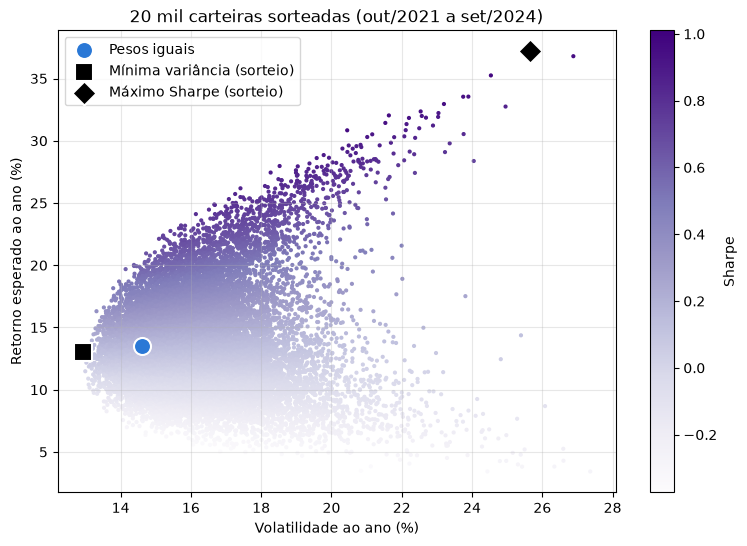

In [10]:
fig, ax = plt.subplots(figsize=(9, 6))
nuvem = ax.scatter(vol_carteiras * 100, retorno_carteiras * 100, c=sharpe_carteiras, cmap="Purples", s=4)
fig.colorbar(nuvem, ax=ax, label="Sharpe")

marcadores = {"Pesos iguais": "o", "Mínima variância": "s", "Máximo Sharpe": "D"}
cores = {"Pesos iguais": "#2a78d6", "Mínima variância": "black", "Máximo Sharpe": "black"}
for nome, w in especiais.items():
    ax.scatter(
        np.sqrt(w @ cov_np @ w) * 100, (w @ mu_np) * 100,
        marker=marcadores[nome], s=150, color=cores[nome], edgecolor="white", linewidth=1.5, label=rotulos[nome],
    )

ax.set_xlabel("Volatilidade ao ano (%)")
ax.set_ylabel("Retorno esperado ao ano (%)")
ax.set_title("20 mil carteiras sorteadas (out/2021 a set/2024)")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

### Bloco 14 · Os pesos escolhidos no sorteio

A tabela relaciona cada ação às três carteiras, em percentual. O teste `> 5` gera valores booleanos e `.sum()` conta quantos são verdadeiros em cada coluna. O limiar de 5% serve apenas para descrever a concentração, não é uma restrição de seleção.

**Resultado verificado:** a carteira de maior Sharpe do sorteio tem **70,1274% em PETR4**, seguida por **12,1203% em VIVT3** e **5,1405% em WEGE3**; são as três posições acima de 5%. A mínima variância do sorteio tem maior posição em **EGIE3, com 29,8194%**. A referência mantém 10% em cada ação.

Concentração traz exposição específica e ajuda a explicar a dependência de trajetórias particulares. Não basta dizer que as ações que subiram mais sempre receberão mais peso: o critério combina médias e covariâncias dos excessos. A tabela não constitui indicação de compra.

In [11]:
tabela_pesos = pd.DataFrame(especiais, index=mu.index) * 100

print("Ações com mais de 5%:")
print((tabela_pesos > 5).sum().rename(index=rotulos))
print()
print("Maior peso (%):")
print(tabela_pesos.max().rename(index=rotulos).round(1))
tabela_pesos.rename(columns=rotulos).round(1)

Ações com mais de 5%:
Pesos iguais                  10
Mínima variância (sorteio)     7
Máximo Sharpe (sorteio)        3
dtype: int64

Maior peso (%):
Pesos iguais                  10.0
Mínima variância (sorteio)    29.8
Máximo Sharpe (sorteio)       70.1
dtype: float64


,Pesos iguais,Mínima variância (sorteio),Máximo Sharpe (sorteio)
ABEV3,10.0,7.9,0.8
EGIE3,10.0,29.8,1.1
ITUB4,10.0,4.7,0.5
PETR4,10.0,4.9,70.1
RADL3,10.0,6.2,3.7
SUZB3,10.0,13.3,4.5
TOTS3,10.0,1.2,1.5
VALE3,10.0,9.6,0.6
VIVT3,10.0,17.2,12.1
WEGE3,10.0,5.1,5.1


### Bloco 15 · O teste fora da amostra

Agora aplicamos aos retornos de teste os pesos escolhidos antes. `fora @ w` representa uma carteira com **rebalanceamento diário aos pesos-alvo, sem custos**; não é uma carteira buy-and-hold. Inserimos um ponto inicial de retorno zero em 30/09/2024, de modo que todas as cotas comecem em 1 na mesma data.

**Preservação do cálculo original correto:** no trecho do CDI, `cumprod()` já é calculado no calendário bancário completo **antes** da atribuição ao DataFrame das cotas. A atribuição apenas alinha os níveis acumulados às datas de preços. Assim são preservados os **502 fatores bancários do teste**, inclusive os quatro dias bancários sem pregão das ações; não havia esse erro no bloco 15 recebido.

**Resultado real:** a cota final do maior Sharpe do sorteio é **1,551462**, a do CDI **1,297162**, a de pesos iguais **1,242123** e a da mínima variância do sorteio **1,173184**. Nesta janela, o maior Sharpe do sorteio termina à frente da referência e do CDI. A figura real está em `figuras/Aula06_B15.png`. A comparação de cotas não elimina a necessidade de comparar volatilidade e concentração.

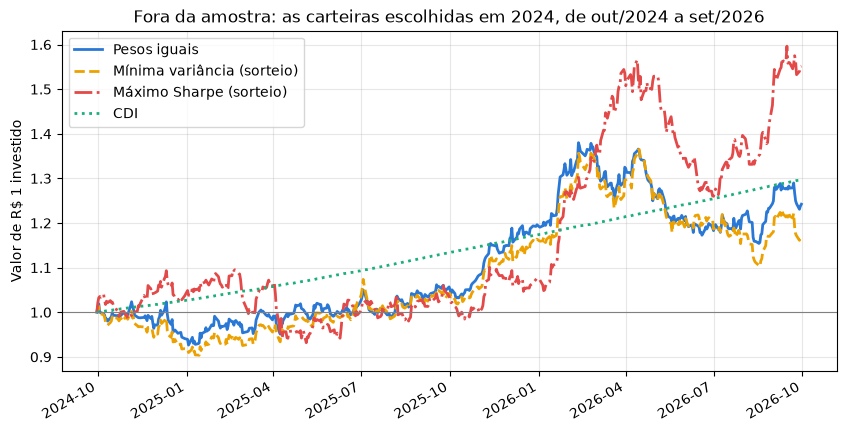

In [12]:
partida = pd.Timestamp(FIM_ESTIMACAO)
fora_com_partida = pd.concat([pd.DataFrame(0.0, index=[partida], columns=fora.columns), fora])

cotas_fora = pd.DataFrame()
for nome, w in especiais.items():
    cotas_fora[nome] = (1 + fora_com_partida @ w).cumprod()

cdi_fora = pd.concat([pd.Series([0.0], index=[partida]), cdi_diario.loc[INICIO_TESTE:] / 100])
cotas_fora["CDI"] = (1 + cdi_fora).cumprod()

ax = cotas_fora.rename(columns=rotulos).plot(
    figsize=(10, 5),
    style=["-", "--", "-.", ":"],
    color=["#2a78d6", "#eda100", "#e34948", "#1baf7a"],
    linewidth=2,
    title="Fora da amostra: as carteiras escolhidas em 2024, de out/2024 a set/2026",
)
ax.axhline(1, color="gray", linewidth=0.8)
ax.set_ylabel("Valor de R$ 1 investido")
ax.set_xlabel("")
ax.grid(alpha=0.3)
plt.show()

### Bloco 16 · Estimado × realizado, com uma definição de Sharpe

A tabela compara o Sharpe estimado com o realizado sob **a mesma definição**: média dos excessos periódicos sobre o CDI dividida por seu desvio padrão amostral e multiplicada por raiz de 252. A função exige índices idênticos das duas cotas para que os retornos cubram os mesmos intervalos. Ausências, poucas observações ou desvio não positivo impedem uma razão válida.

O retorno realizado ao ano continua sendo o **CAGR**, calculado com dias corridos. A volatilidade realizada é o desvio amostral dos retornos da carteira, vezes raiz de 252. Portanto, o desvio usado na coluna de volatilidade não é automaticamente o mesmo denominador do Sharpe, que usa os excessos.

**Resultados realizados:** pesos iguais: CAGR **11,4588%**, volatilidade **14,9136%**, Sharpe **−0,072850**; mínima variância do sorteio: **8,3196%**, **15,2030%**, **−0,258778**; maior Sharpe do sorteio: **24,5764%**, **18,4741%**, **0,583060**. Esses números não autorizam inventar uma derrota da otimização: nesta janela, o maior Sharpe do sorteio venceu a referência em retorno e Sharpe, mas teve volatilidade maior.

A anualização aritmética estimada e o CAGR realizado são quantidades diferentes. Comparar o retorno esperado mostrado no gráfico diretamente com o CAGR não é um teste de identidade. Tampouco o sinal do Sharpe periódico equivale, em todos os casos, ao sinal da diferença entre retornos compostos.

In [13]:
def retorno_anual(serie):
    """CAGR: retorno composto anual, com anos em dias corridos."""
    anos = (serie.index[-1] - serie.index[0]).days / 365.25
    return (serie.iloc[-1] / serie.iloc[0]) ** (1 / anos) - 1


def volatilidade_anual(serie, periodos_por_ano=252):
    """Desvio padrão amostral dos retornos da carteira, anualizado."""
    return serie.pct_change(fill_method=None).dropna().std(ddof=1) * periodos_por_ano ** 0.5


def sharpe(serie, cdi, periodos_por_ano=252):
    """Média dos excessos periódicos / desvio amostral dos excessos, anualizada."""
    if not serie.index.equals(cdi.index):
        raise ValueError("As duas cotas devem cobrir os mesmos intervalos")
    retorno_serie = serie.pct_change(fill_method=None).iloc[1:]
    retorno_cdi = cdi.pct_change(fill_method=None).iloc[1:]
    excessos = retorno_serie - retorno_cdi
    if len(excessos) < 2 or excessos.isna().any() or excessos.std(ddof=1) <= 0:
        raise ValueError("Excessos insuficientes, ausentes ou sem volatilidade positiva")
    return excessos.mean() / excessos.std(ddof=1) * periodos_por_ano ** 0.5


comparacao = pd.DataFrame(index=list(especiais))
for nome in especiais:
    comparacao.loc[nome, "Sharpe esperado"] = dentro_amostra.loc[nome, "Sharpe"]
    comparacao.loc[nome, "Sharpe realizado"] = sharpe(cotas_fora[nome], cotas_fora["CDI"])
    comparacao.loc[nome, "Retorno realizado ao ano (%)"] = retorno_anual(cotas_fora[nome]) * 100
    comparacao.loc[nome, "Volatilidade realizada (%)"] = volatilidade_anual(cotas_fora[nome]) * 100

comparacao.rename(index=rotulos).round(2)

,Sharpe esperado,Sharpe realizado,Retorno realizado ao ano (%),Volatilidade realizada (%)
Pesos iguais,0.15,-0.07,11.46,14.91
Mínima variância (sorteio),0.14,-0.26,8.32,15.20
Máximo Sharpe (sorteio),1.01,0.58,24.58,18.47


### Bloco 17 · Os pesos sorteados são válidos?

A soma dos pesos de cada linha precisa ser 1 e nenhum peso pode ser negativo. `sum(axis=1)` soma por carteira, `np.allclose` tolera a pequena imprecisão de ponto flutuante e `.all()` exige que todas as comparações booleanas sejam verdadeiras.

**Saída real:** `True` e `True`. A validação cobre a restrição de soma e sinal dos 200 mil pesos; não comprova que o sorteio cobre bem todo o simplex, que as estimativas são boas ou que alguma carteira seja ótima fora da amostra.

In [14]:
print("Todas as carteiras somam 1?", np.allclose(pesos.sum(axis=1), 1))
print("Nenhum peso negativo?", (pesos >= 0).all())

Todas as carteiras somam 1? True
Nenhum peso negativo? True


### Bloco 18 · A fórmula com matrizes confere com a série?

Para a carteira de maior Sharpe do sorteio, comparamos a volatilidade obtida por `sqrt(w @ cov_np @ w)` com a calculada diretamente da série `dentro @ w`. Os dois caminhos usam a mesma amostra completa, os mesmos pesos e desvio amostral com anualização por 252.

**Saída real:** **25,6415%** pelos dois caminhos, até a quarta casa decimal. Essa concordância é uma checagem da implementação da variância, não valida a previsão de médias ou o desempenho futuro. A auditoria privada também verifica o Sharpe dos excessos e não adiciona células curriculares ao notebook entregue.

In [15]:
w = especiais["Máximo Sharpe"]
vol_formula = np.sqrt(w @ cov_np @ w)
vol_serie = (dentro @ w).std() * 252 ** 0.5

print(f"Pela fórmula com matrizes: {vol_formula * 100:.4f}%")
print(f"Pela série de retornos:    {vol_serie * 100:.4f}%")

Pela fórmula com matrizes: 25.6415%
Pela série de retornos:    25.6415%


### Bloco 19 · Conferência com uma biblioteca (opcional)

A PyPortfolioOpt resolve o problema de mínima variância numericamente, sem depender dos 20 mil sorteios, sob as mesmas restrições padrão de pesos entre zero e um e soma 1. Usamos `mu` e `cov` dos **retornos dos ativos**. Embora a chamada receba as médias, a solução de mínima variância é definida pela covariância e pelas restrições.

Mantemos a instalação com `%pip` e a estrutura `try`/`except` atualizadas pelo usuário. **O tratamento protege somente o import contra `ModuleNotFoundError`.** A linha de instalação está fora do `try`, e erros de instalação, outros erros de importação ou falhas do solver não estão cobertos. Reiniciar o kernel pode ser necessário após instalação; o aviso não garante ausência de erro.

Nesta execução a dependência já estava instalada. `%pip` foi realmente executado com acesso ao índice desabilitado no ambiente de produção, sem coleta de dados e sem simulação de saída. Em uso local, esta linha pode consultar a rede ou instalar a biblioteca; é opcional e deve ser executada conscientemente.

**Saída real:** volatilidade mínima do sorteio **12,93%** e da biblioteca **12,73%**. Valores sem arredondamento: **12,929072238%** e **12,734183173%**, diferença de **0,194889065 ponto percentual**. O solver reportou `optimal`; trata-se de um mínimo numérico sujeito a tolerâncias, não de uma garantia exata fora da amostra. A impressão é **volatilidade (%)**, não variância (%). A auditoria independente com NumPy e SciPy concorda dentro das tolerâncias declaradas.

In [16]:
%pip install pyportfolioopt --quiet

try:
    from pypfopt import EfficientFrontier
except ModuleNotFoundError:
    print("A PyPortfolioOpt ainda não está disponível neste kernel.")
    print("Se a instalação acima terminou sem erro, reinicie o kernel (Kernel → Restart Kernel)")
    print("e rode o notebook de novo.")
else:
    ef = EfficientFrontier(mu, cov)
    ef.min_volatility()
    vol_exata = ef.portfolio_performance()[1]
    print(f"Volatilidade mínima (sorteio):    {vol_carteiras.min() * 100:.2f}%")
    print(f"Volatilidade mínima (biblioteca): {vol_exata * 100:.2f}%")

Note: you may need to restart the kernel to use updated packages.


Volatilidade mínima (sorteio):    12.93%
Volatilidade mínima (biblioteca): 12.73%


### Bloco 20 · O que os números dizem

Dentro da amostra, o maior Sharpe do sorteio caiu de uma estimativa de **1,010156** para um realizado de **0,583060**, mas ainda superou os **−0,072850** dos pesos iguais no teste. Seu CAGR foi **24,5764%**, contra **11,4588%** da referência, e sua volatilidade foi **18,4741%**, contra **14,9136%**. Sua posição de 70,1274% em PETR4 faz parte da interpretação: não é uma melhora sem contrapartidas.

A mínima variância do sorteio passou de volatilidade estimada de **12,9291%** para realizada de **15,2030%**. No teste, essa volatilidade foi **maior**, e não menor, que a da carteira de pesos iguais. Seu CAGR de **8,3196%** e seu Sharpe de **−0,258778** também ficaram abaixo dos da referência. Portanto, não vamos afirmar que a mínima variância foi a mais estável ou que manteve uma promessa de menor risco fora da amostra.

O CDI terminou em 1,297162 por unidade inicial, acima das cotas de pesos iguais e da mínima variância do sorteio, mas abaixo da de maior Sharpe do sorteio. Este resultado refuta uma história pronta de que “a otimização sempre perde” nesta janela, sem provar a história oposta de que ela sempre ganha.

A lição é distinguir **seleção**, **estimação** e **teste**. Escolher o melhor resultado histórico de uma nuvem não prova generalização; perder parte do Sharpe estimado também não implica necessariamente perder da referência. Para avaliar robustez, seriam necessários outros cortes de datas e métodos, com custos, sem escolher a narrativa depois de observar o teste.

### Bloco 21 · O que esta análise não mostra

- **Um corte de datas:** o resultado pertence a esta divisão. Repetir em várias janelas, sem ajustar o método a posteriori para favorecer o teste, seria mais informativo (exercício 2).
- **Estimativas simples:** médias e covariâncias históricas têm erro. Otimizar essas estimativas não equivale a conhecer o futuro. A mínima variância também sofre mudança das covariâncias.
- **Nuvem finita:** Dirichlet com densidade uniforme no simplex não assegura boa cobertura das carteiras concentradas; o extremo do sorteio não é o extremo global. O bloco 19 resolve apenas o problema numérico de mínima variância adotado, não toda a fronteira e muito menos o futuro.
- **Rebalanceamento diário sem custos:** corretagem, impostos, spread, liquidez e restrições operacionais não foram modelados. Os preços ajustados e a reinversão implícita não são um livro-caixa de operações reais.
- **Concentração:** há pesos não negativos, mas não há teto por ação. O exercício 1 impõe um filtro para observar essa troca.
- **Risco limitado ao modelo:** volatilidade não representa sozinha perdas extremas, drawdown, liquidez, crédito ou todos os riscos econômicos. O CDI é a referência escolhida, não uma promessa de taxa futura.
- **Snapshots:** os arquivos permitem reproduzir esta execução, não corrigem limitações ou revisões do provedor. Não houve recaptura para ajustar a história aos resultados.
- **Unidades:** Sharpe é adimensional; retorno esperado é média anualizada; CAGR é retorno composto; volatilidade é desvio anualizado. Raiz de 252 é uma convenção cuja interpretação depende da dinâmica dos retornos.

### Bloco 22 · Para praticar: cinco exercícios

1. **Teto de 20% por ação.** Crie `permitidas = pesos.max(axis=1) <= 0.20`, confira se existe ao menos uma linha permitida e escolha o maior Sharpe apenas nesse subconjunto. Mapeie a posição local de volta à linha original antes de buscar os pesos. Repita o teste com CDI nos mesmos intervalos e compare CAGR, volatilidade e Sharpe. Não presuma melhora fora da amostra.
2. **Outra janela.** Mude `FIM_ESTIMACAO` para `"2023-09-30"` e `INICIO_TESTE` para `"2023-10-01"`, e rode tudo novamente usando os mesmos snapshots. O corte de estimação cai em um sábado: ajuste o ponto inicial das cotas ao último índice efetivo de `dentro`, com `partida = dentro.index[-1]`, e não crie um pregão fictício. Registre tamanhos, datas e pesos; reescreva a interpretação com os novos números, em uma cópia separada.
3. **Outra semente.** Troque `SEMENTE`, mantenha 20 mil candidatos e compare pesos, posições dos extremos e métricas. Distinga variação do sorteio de variação dos dados. Registre a versão do NumPy.
4. **Mais carteiras.** Eleve `N_CARTEIRAS` a 100 mil em uma cópia e compare a menor volatilidade com o mínimo numérico do bloco 19. Para garantir que o mínimo não aumente em uma comparação, preserve as 20 mil linhas antigas e acrescente novas; dois sorteios independentes não têm essa garantia. Compare também o tempo de execução e a concentração.
5. **Otimização do mesmo Sharpe.** Crie um novo `EfficientFrontier(mu_excesso, cov_excesso)` e use `max_sharpe(risk_free_rate=0)` para otimizar a razão de **excessos** desta aula, em vez de substituir silenciosamente seu denominador pela volatilidade dos ativos. Confira se há média de excesso positiva e trate eventuais falhas do solver. Compare o Sharpe obtido diretamente das séries, os pesos e a concentração com o maior Sharpe do sorteio. Não chame essa única carteira de “toda a fronteira”, nem seu desempenho futuro de ótimo. Este é um exercício proposto: a entrega executa a conferência de mínima variância do bloco 19, não os cinco exercícios.

### Bloco 23 · O que aprendemos

**Em finanças:** a média de retorno de uma carteira é ponderada pelos pesos, enquanto sua volatilidade depende das covariâncias. O modelo usa volatilidade como medida de risco, sem esgotar todos os riscos. A fronteira eficiente é uma propriedade do conjunto factível e das estimativas; uma nuvem de 20 mil pontos é somente uma aproximação visual. Os extremos do sorteio não garantem superioridade sobre pesos iguais e não são garantias fora da amostra.

O Sharpe convencional desta aula usa média e desvio amostral dos **excessos periódicos** com intervalos compatíveis. O CAGR foi mantido para o retorno composto realizado, não como substituto da média no Sharpe. Os resultados efetivos foram favoráveis ao maior Sharpe do sorteio nesta janela, mas a mínima variância do sorteio não foi a menos volátil no teste. Custos e rebalanceamento real continuam fora do modelo.

**Em Python:** arrays do NumPy não preservam rótulos; validar ordem é parte da conta financeira. `.to_numpy()`, `@`, `np.sqrt`, `default_rng`, `dirichlet`, `argmin` e `argmax` permitem trabalhar com muitas carteiras sem um laço por candidato. `axis=1` agrega por linha e `np.allclose` trata tolerâncias. `try`/`except ModuleNotFoundError` lida com um erro previsto de importação, não com qualquer erro do notebook.

### Bloco 24 · Próxima aula

Até aqui usamos ações brasileiras e observamos como suas covariâncias e pesos afetam a volatilidade neste universo finito. Não identificamos um piso empírico universal de risco, e não há motivo para prometer que adicionar outro ativo reduzirá o risco de toda carteira.

Na próxima aula podemos buscar históricos de Bitcoin e Ethereum por uma API pública de corretora de criptomoedas, para aprender parâmetros, paginação, fuso horário e datas em milissegundos. A escolha da fonte será didática; esta aula não depende da afirmação de que esses ativos estejam ausentes de outros provedores. Uma eventual diversificação e seu resultado precisariam ser medidos na amostra e nas restrições escolhidas. Criptoativos também introduzem riscos próprios e não garantem redução de volatilidade.

## Glossário da aula

| Termo | Significado nesta aula |
|---|---|
| Retorno simples | Variação entre dois preços ou níveis consecutivos de cota |
| Retorno esperado | Média histórica diária multiplicada por 252; estimativa, não promessa |
| CAGR | Taxa composta anual entre cota inicial e final, usando anos em dias corridos |
| Variância | Dispersão quadrática dos retornos; unidade de retorno ao quadrado |
| Volatilidade | Desvio padrão amostral anualizado dos retornos, apresentado em % |
| Covariância | Medida de associação conjunta dos desvios de dois retornos |
| Excesso periódico | Retorno da carteira menos retorno do CDI acumulado no mesmo intervalo |
| Sharpe | Média dos excessos / desvio amostral dos excessos, vezes raiz de 252; adimensional |
| Fronteira eficiente | Conjunto factível não dominado em retorno esperado e volatilidade |
| Mínima variância (sorteio) | Menor volatilidade entre as 20 mil linhas sorteadas; não mínimo global |
| Máximo Sharpe (sorteio) | Maior Sharpe entre as 20 mil linhas sorteadas; não máximo global |
| Mínimo numérico | Solução do problema de mínima variância pelo solver, sujeita a tolerâncias |
| Simplex de pesos | Conjunto de vetores não negativos cuja soma é 1 |
| Dirichlet(1) | Distribuição de densidade uniforme no simplex; não assegura cobertura concentrada |
| Erro de estimação | Diferença entre o parâmetro estimado e o que se deseja conhecer |
| Fora da amostra | Período posterior que não foi usado para selecionar os pesos |
| Rebalanceamento diário | Restauração diária dos pesos-alvo; nesta simulação sem custos |
| Snapshot | Arquivo congelado da base efetivamente usada, sem nova coleta |
| Array | Estrutura numérica do NumPy sem os rótulos financeiros do pandas |
| `@` | Operador de multiplicação matricial |
| `axis=1` | Agregação ao longo das colunas, produzindo um resultado por linha |
| Semente | Estado inicial do gerador; exige código e ambiente identificados para reprodução |
| `try` / `except` | Tratamento de um erro explicitamente previsto no bloco protegido |

## Referências metodológicas e proveniência

A fonte curricular é `fontes/NOTEBOOK_RECEBIDO_AULA06.ipynb`, acompanhada por `fontes/ROTEIRO_RECEBIDO_AULA06.md`; ambas foram mantidas intactas. As referências primárias preservadas na auditoria de fontes incluem William F. Sharpe, *The Sharpe Ratio* (1994), a documentação de `Generator.dirichlet` e de compatibilidade do gerador NumPy e a documentação/repositório da PyPortfolioOpt. O registro de fontes está em `fontes/CITATION_LEDGER.json`; o presente capítulo não depende de uma nova coleta de dados de mercado.

A definição de Sharpe foi harmonizada com autorização explícita. A mudança de método, o ambiente, os hashes e os passos para atualizar a cópia local constam de `ALTERACOES_AULA06.md`. As métricas completas e a validação desta execução estão em `METRICAS_AULA06.json` e `QA_AULA06.json`.

*Python Finance Lab · Conteúdo exclusivamente educacional. Não constitui recomendação de investimento.*